In [1]:
import cv2

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cbook import get_sample_data
from PIL import Image

In [2]:
image_path = get_sample_data("grace_hopper.jpg", asfileobj=False)
with Image.open(image_path) as source:
    image = np.asarray(source.convert("L"))

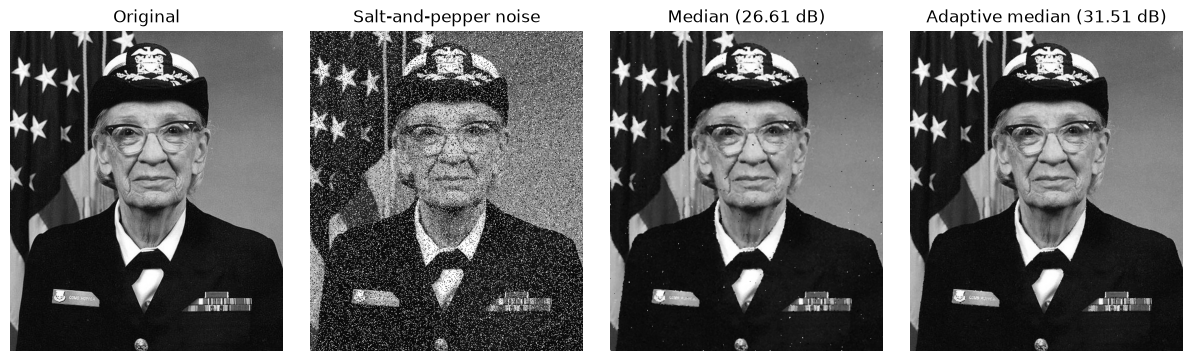

In [3]:
# Question 1
def adaptive_median(noisy, initial_size, maximum_size):
    result = noisy.copy()
    pending = np.ones(noisy.shape, dtype=bool)

    for size in range(initial_size, maximum_size + 1, 2):
        kernel = np.ones((size, size), dtype=np.uint8)
        minimum = cv2.erode(noisy, kernel, borderType=cv2.BORDER_REPLICATE)
        maximum = cv2.dilate(noisy, kernel, borderType=cv2.BORDER_REPLICATE)
        median = cv2.medianBlur(noisy, size)

        good_median = (minimum < median) & (median < maximum)
        good_pixel = (minimum < noisy) & (noisy < maximum)
        resolved = pending & good_median
        result[resolved & ~good_pixel] = median[resolved & ~good_pixel]
        pending &= ~resolved

    result[pending] = median[pending]
    return result


initial_size = 3
maximum_size = 7
rng = np.random.default_rng(42)
noise = rng.random(image.shape)
noisy = image.copy()
noisy[noise < 0.1] = 0
noisy[noise > 0.9] = 255

median = cv2.medianBlur(noisy, initial_size)
adaptive = adaptive_median(noisy, initial_size, maximum_size)
median_psnr = cv2.PSNR(image, median)
adaptive_psnr = cv2.PSNR(image, adaptive)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout="constrained")
titles = (
    "Original",
    "Salt-and-pepper noise",
    f"Median ({median_psnr:.2f} dB)",
    f"Adaptive median ({adaptive_psnr:.2f} dB)",
)
for ax, result, title in zip(axes, (image, noisy, median, adaptive), titles):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

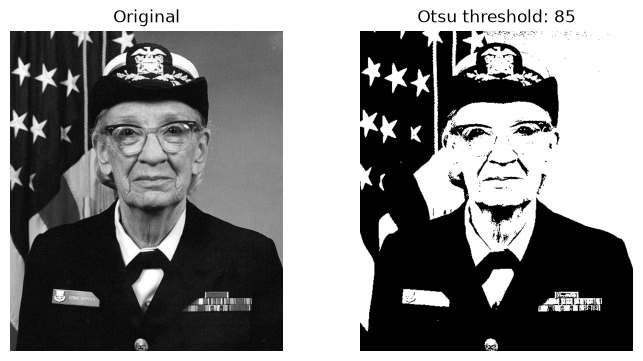

In [4]:
# Question 2
threshold, segmented = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), layout="constrained")
for ax, result, title in zip(axes, (image, segmented), ("Original", f"Otsu threshold: {threshold:.0f}")):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()